[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/17_recommender_systems.ipynb)

# 17 · Recommender Systems: Filling In a Matrix That's Mostly Empty

**Part 2 — Classical unsupervised learning** · Notebook 17 of 27

Netflix has millions of users and tens of thousands of titles, and any one user has rated a tiny fraction of them. The question a recommender answers is: **for each user and each title they haven't seen, how much would they like it?** Written as a table with one row per user and one column per item, that's a matrix where 95–99% of the entries are missing, and we need to fill in the blanks.

This sounds impossible until you notice that tastes aren't random. People who loved the same five movies tend to agree on a sixth. Movies are mostly blends of a few genres, and people mostly have opinions about a few genres. Mathematically: the full rating matrix is approximately **low rank**, the same idea behind PCA (notebook 16). This notebook builds the two classic families of recommenders on that idea: **matrix factorization**, which learns a short vector ("embedding") for every user and item, and **collaborative filtering**, which recommends what similar users or similar items suggest.

**What you'll learn**

1. The problem: a huge, sparse, biased matrix
2. Why low rank? Tastes are driven by a few factors
3. Why we can't just run the SVD
4. Matrix factorization with $r = 1$, by hand: alternating least squares
5. General matrix factorization: rank, regularization, and biases
6. What the embeddings learned
7. Collaborative filtering: cosine vs. Pearson, user-based vs. item-based
8. Head to head on held-out ratings
9. From predicted ratings to recommendations: ranking metrics
10. Real-world problems: cold start, implicit feedback, feedback loops

*Course map: ISYE 4600 W4 (Recommender Systems: sparsity, low-rank models, SVD and truncated SVD, matrix factorization, alternating least squares, regularization, collaborative filtering with cosine and Pearson similarity, user- and item-based prediction) and HW2 Q5 (coordinate descent for $\min\sum_{(i,j)\in\Omega}(M_{ij} - u_iv_j)^2$, user- and item-based collaborative filtering with distance-based similarities).*

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")
import time
print("Ready ✓")

Setup complete ✓
Ready ✓


---
## 1. The problem: a huge, sparse, biased matrix

Real rating datasets (MovieLens, Netflix) need a download and a license agreement, so we'll build a realistic **simulated** one whose hidden structure we know. That lets us check our methods against the truth, which you can never do with real data. (Exercise 6 points to MovieLens if you want to try the real thing.)

The simulation: 400 users and 250 movies. Each movie belongs mainly to one of five genres; each user has a taste (positive or negative) for each genre; on top of that, some users rate everything generously and some movies are simply better. Users mostly watch popular movies and movies they expect to like, and they rate only what they watch.

15,596 ratings out of 100,000 possible (15.6% observed)
average observed rating 3.87 vs. average over ALL user–movie pairs 3.39


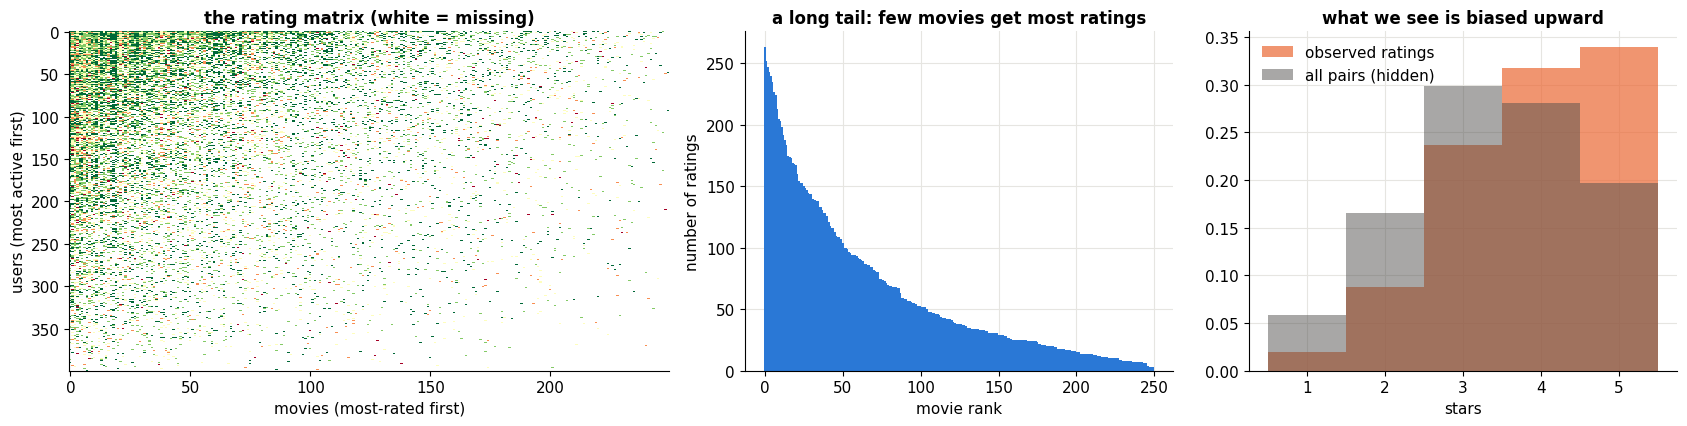

In [2]:
r_ = np.random.default_rng(0)
n_users, n_items, n_genres = 400, 250, 5
genres = np.array(["Action", "Comedy", "Drama", "Sci-Fi", "Romance"])
item_genre = r_.integers(0, n_genres, n_items)
item_f = np.eye(n_genres)[item_genre] + r_.normal(0, 0.3, (n_items, n_genres))   # mostly one genre, a little of others
user_f = r_.normal(0, 1, (n_users, n_genres))                                   # taste for each genre
user_bias, item_bias = r_.normal(0, 0.4, n_users), r_.normal(0, 0.5, n_items)
true_pref = 3.4 + user_bias[:, None] + item_bias[None, :] + 0.8 * user_f @ item_f.T   # what each user WOULD rate

popularity = np.exp(r_.normal(0, 1, n_items)); activity = np.exp(r_.normal(0, 0.8, n_users))
p_watch = np.outer(activity, popularity); p_watch = p_watch / p_watch.mean() * 0.15
p_watch = np.clip(p_watch * np.exp(0.5 * (true_pref - true_pref.mean())), 0, 1)   # people pick what they expect to like
observed = r_.random((n_users, n_items)) < p_watch
ratings = np.clip(np.round(true_pref + r_.normal(0, 0.5, true_pref.shape)), 1, 5)  # 1–5 stars, with noise
titles = np.array([f"{genres[g]} #{i:03d}" for i, g in enumerate(item_genre)])

print(f"{observed.sum():,} ratings out of {observed.size:,} possible ({observed.mean():.1%} observed)")
print(f"average observed rating {ratings[observed].mean():.2f} vs. average over ALL user–movie pairs {ratings.mean():.2f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4), gridspec_kw=dict(width_ratios=[1.4, 1, 1]))
order_u, order_i = np.argsort(-observed.sum(1)), np.argsort(-observed.sum(0))
axes[0].imshow(np.where(observed, ratings, np.nan)[order_u][:, order_i], aspect="auto", cmap="RdYlGn", vmin=1, vmax=5, interpolation="nearest")
axes[0].set(xlabel="movies (most-rated first)", ylabel="users (most active first)", title="the rating matrix (white = missing)"); axes[0].grid(False)
axes[1].bar(range(n_items), np.sort(observed.sum(0))[::-1], color=C["blue"], width=1.0)
axes[1].set(xlabel="movie rank", ylabel="number of ratings", title="a long tail: few movies get most ratings")
axes[2].hist(ratings[observed], bins=np.arange(0.5, 6), alpha=0.7, density=True, color=C["orange"], label="observed ratings")
axes[2].hist(ratings.ravel(), bins=np.arange(0.5, 6), alpha=0.5, density=True, color=C["muted"], label="all pairs (hidden)")
axes[2].set(xlabel="stars", title="what we see is biased upward"); axes[2].legend()
fig.tight_layout(); plt.show()

Three features of real rating data, all present here:

- **Sparsity.** About 85% of the matrix is empty, and real datasets are far sparser (Netflix Prize: ~1%).
- **A long tail.** A few blockbusters have hundreds of ratings; most movies have a handful.
- **Missing not at random.** People watch what they expect to enjoy, so observed ratings skew high. The missing entries aren't a random sample of the matrix, which quietly biases every method below.

> 🤔 **Question: If we already know what a user liked before, why is prediction still hard?** (ISYE W4)
>
> Because the question is always about the items they *haven't* rated, and for a typical user that's nearly all of them. Their own history covers a few dozen items; to say anything about the rest, a model has to borrow strength from **other users**. That's the "collaborative" in collaborative filtering, and it's why the assumption in the next section matters so much.

We hold out 20% of the observed ratings as a test set and never fit on them:

In [3]:
obs_idx = np.argwhere(observed); r_.shuffle(obs_idx)
n_test = len(obs_idx) // 5
test_idx, train_idx = obs_idx[:n_test], obs_idx[n_test:]
M = np.zeros_like(observed); M[train_idx[:, 0], train_idx[:, 1]] = True      # training mask
R_train = np.where(M, ratings, np.nan)

def rmse(pred, idx=test_idx):
    """Root mean squared error on a set of (user, item) pairs."""
    return np.sqrt(np.mean((np.clip(pred[idx[:, 0], idx[:, 1]], 1, 5) - ratings[idx[:, 0], idx[:, 1]]) ** 2))

mu = np.nanmean(R_train)
results = {"global mean": rmse(np.full(ratings.shape, mu)), "oracle (true preferences)": rmse(true_pref)}
print(f"predict the global mean {mu:.2f} for everything: test RMSE {results['global mean']:.3f}")
print(f"oracle that knows each user's true preference: test RMSE {results['oracle (true preferences)']:.3f}  (the noise floor)")

predict the global mean 3.87 for everything: test RMSE 1.039
oracle that knows each user's true preference: test RMSE 0.507  (the noise floor)


The oracle's error isn't zero, because real ratings are noisy and rounded to whole stars. Every method lands somewhere between the global mean (≈1.04) and the oracle (≈0.51).

---
## 2. Why low rank? Tastes are driven by a few factors

ISYE W4's argument: *movies blend a small number of genres; users have preferences over a few genres; so preferences lie in a low-dimensional space.* In our simulation that's literally true: apart from the biases, every rating is a dot product of a 5-number user taste vector and a 5-number movie genre vector. So the **complete** preference matrix (which we normally never see) has a sharp drop in its singular values:

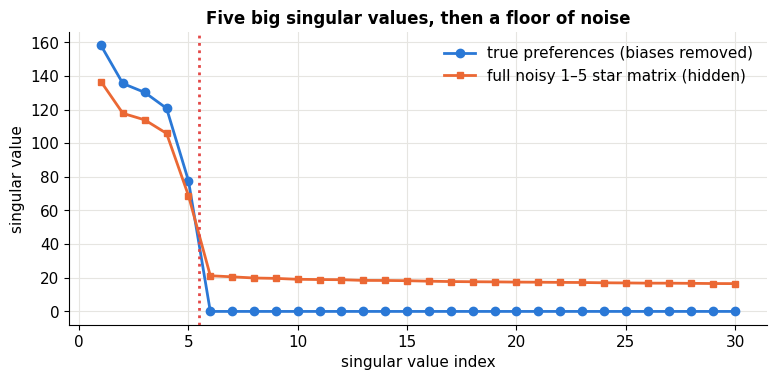

In [4]:
centered_truth = true_pref - true_pref.mean(1, keepdims=True) - true_pref.mean(0, keepdims=True) + true_pref.mean()
s_true = np.linalg.svd(centered_truth, compute_uv=False)
s_noisy = np.linalg.svd(ratings - ratings.mean(1, keepdims=True) - ratings.mean(0, keepdims=True) + ratings.mean(), compute_uv=False)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(range(1, 31), s_true[:30], "o-", color=C["blue"], label="true preferences (biases removed)")
ax.plot(range(1, 31), s_noisy[:30], "s-", color=C["orange"], ms=4, label="full noisy 1–5 star matrix (hidden)")
ax.axvline(5.5, color=C["red"], ls=":"); ax.set(xlabel="singular value index", ylabel="singular value", title="Five big singular values, then a floor of noise")
ax.legend(); plt.show()

Five singular values stand out (the five genres); after that, the true matrix is exactly zero and the noisy one levels off at a noise floor. By the Eckart–Young theorem (notebook 01), truncating the SVD to the top $r$ terms gives the **best rank-$r$ approximation** in squared error: it keeps the dominant patterns and drops noise.

> 🤔 **Question: What assumption justifies recommending items liked by one user to another?** (ISYE W4)
>
> That users aren't arbitrary: their preferences are generated by a **shared, small set of factors**, so two users who agree on many items likely share those factors and will agree on others. If every user's taste were an independent random draw over every item, the rating matrix would be full rank and the observed entries would say nothing about the missing ones.

---
## 3. Why we can't just run the SVD

The SVD needs a **complete** matrix. Ours is 85% missing. The obvious hacks fill the gaps with something: zeros, or each movie's average. That injects fake data (ISYE W4: *"inject fake data/assumptions ❌"*):

In [5]:
def truncated_svd_fill(fill, r):
    X = np.where(M, ratings, fill)
    U, s, Vt = np.linalg.svd(X, full_matrices=False)
    return (U[:, :r] * s[:r]) @ Vt[:r]

item_means = np.where(M.sum(0) > 0, np.nansum(R_train, 0) / np.maximum(M.sum(0), 1), mu)
rows = []
for r in [1, 2, 5, 10, 20]:
    rows.append(dict(rank=r, **{"fill with 0": rmse(truncated_svd_fill(0.0, r)),
                                "fill with movie average": rmse(truncated_svd_fill(np.broadcast_to(item_means, ratings.shape), r))}))
pd.DataFrame(rows).set_index("rank").round(3)

,fill with 0,fill with movie average
rank,,
1,2.644,0.942
2,2.585,0.908
5,2.512,0.848
10,2.593,0.859
20,2.760,0.894


Filling with zeros is a disaster: the SVD dutifully learns that "most ratings are 0 stars", and predictions collapse toward zero (we clip them to 1). Filling with movie averages is far better (and, as we'll see, even beats a simple bias model), but the model spends much of its effort reproducing made-up averages that make up 85% of the matrix, as if every user had rated every movie at its average. Section 5 does better by not inventing anything. What we want is a factorization that **only looks at the observed entries**.

---
## 4. Matrix factorization with $r = 1$, by hand

Model every rating as a product $x_{ij} \approx u_iv_j$, with one number $u_i$ per user and one number $v_j$ per item (rank 1; ISYE W4), and fit only the observed set $\Omega$:

$$\min_{u, v}\;\sum_{(i,j)\in\Omega}\big(x_{ij} - u_iv_j\big)^2.$$

Missing entries are **ignored, not zeroed**. Jointly in $(u, v)$ this isn't convex (the product $u_iv_j$ is the culprit), but fix $v$ and it's an ordinary least-squares problem in each $u_i$ separately, and vice versa. Setting the derivative to zero (HW2 Q5):

$$\frac{\partial}{\partial u_i}\sum_{j:(i,j)\in\Omega}(x_{ij} - u_iv_j)^2 = -2\sum_j v_j(x_{ij} - u_iv_j) = 0 \;\;\Longrightarrow\;\; u_i = \frac{\sum_{j:(i,j)\in\Omega} v_jx_{ij}}{\sum_{j:(i,j)\in\Omega} v_j^2}, \qquad v_j = \frac{\sum_{i:(i,j)\in\Omega} u_ix_{ij}}{\sum_{i:(i,j)\in\Omega} u_i^2}.$$

Alternate the two updates: **alternating least squares** (ALS), a block coordinate descent like k-means (notebook 14), so the objective never increases. Here's ISYE's 5 × 5 example:

In [6]:
X5 = np.array([[np.nan, np.nan, 4, np.nan, np.nan],
               [5, np.nan, np.nan, 3, np.nan],
               [1, np.nan, 2, np.nan, 2],
               [np.nan, 2, 5, np.nan, np.nan],
               [4, np.nan, np.nan, 3, 2]])
O5 = ~np.isnan(X5); X0 = np.nan_to_num(X5)
u, v = np.ones(5), np.ones(5)
history = []
for it in range(50):
    u = (X0 * O5 * v[None, :]).sum(1) / (O5 * v[None, :] ** 2).sum(1)      # each user: 1-D least squares
    v = (X0 * O5 * u[:, None]).sum(0) / (O5 * u[:, None] ** 2).sum(0)      # each item: 1-D least squares
    history.append(((X0 - np.outer(u, v)) ** 2 * O5).sum())
scale = 3 / v[0]; u, v = u / scale, v * scale                              # u·v is unchanged; match the slide's scaling (v₁ = 3)
print(f"objective after 1, 2, 5, 50 rounds: {history[0]:.3f}, {history[1]:.3f}, {history[4]:.3f}, {history[-1]:.3f}")
print("user factors u:", u.round(2), "   item factors v:", v.round(2))
pred5 = np.outer(u, v)
show = pd.DataFrame([[f"{X5[i, j]:.0f}" if O5[i, j] else f"({pred5[i, j]:.1f})" for j in range(5)] for i in range(5)],
                    index=[f"user {i + 1}" for i in range(5)], columns=[f"item {j + 1}" for j in range(5)])
print("\nobserved ratings, and predictions for the missing ones in parentheses:"); show

objective after 1, 2, 5, 50 rounds: 3.435, 1.889, 1.845, 1.786
user factors u: [1.09 1.61 0.54 1.36 1.32]    item factors v: [3.   1.47 3.68 2.03 1.83]

observed ratings, and predictions for the missing ones in parentheses:


,item 1,item 2,item 3,item 4,item 5
user 1,(3.3),(1.6),4,(2.2),(2.0)
user 2,5,(2.4),(5.9),3,(2.9)
user 3,1,(0.8),2,(1.1),2
user 4,(4.1),2,5,(2.8),(2.5)
user 5,4,(1.9),(4.9),3,2


ISYE's slide shows u ≈ (1.3, 1.6, 0.6, 1.4, 1.3) and v ≈ (3, 1.4, 3, 2, 1.8). Our converged values have the same pattern (user 3 lowest, items 1 and 3 highest) but differ in places, e.g. $v_3 \approx 3.7$. They also fit better: the slide's factors give a squared error of 2.54 on the observed entries, ours 1.79, so the slide is best read as a rounded snapshot from early in the iterations. Also notice the prediction 5.9 for user 2, item 3: the model knows nothing about the 1–5 scale, so in practice predictions are clipped. Three more things to notice:

- The objective falls fast (3.44 → 1.89 → 1.85 in the first rounds) and then creeps down, the usual coordinate-descent profile.
- The factorization is only defined **up to scale**: multiplying every $u_i$ by $c$ and dividing every $v_j$ by $c$ gives identical predictions. We rescaled so $v_1 = 3$ like the slide. (Regularization, next section, removes this ambiguity.)
- Rank 1 is a strong assumption: each user is one "enthusiasm" number and each item one "appeal" number, so every user ranks the items in the **same order** ($v$'s order). User 3 rates low across the board, so all of user 3's predictions are low. Real tastes need more than one dimension.

---
## 5. General matrix factorization

With rank $r$, each user gets a vector $u_i \in \mathbb{R}^r$ and each item a vector $v_j \in \mathbb{R}^r$, and the prediction is the dot product $\hat x_{ij} = u_i^\top v_j$: the user's taste profile matched against the item's profile. Two additions make it work well in practice.

**Regularization** (ISYE W4). Without it, a user with three ratings gets a factor vector that fits those three exactly and predicts nonsense elsewhere. Add a ridge penalty (notebook 07):

$$\min_{U, V}\sum_{(i,j)\in\Omega}\big(x_{ij} - u_i^\top v_j\big)^2 + \lambda\big(\|U\|_F^2 + \|V\|_F^2\big).$$

Each ALS step is now a small **ridge regression**: with $V_{\Omega_i}$ the rows of $V$ for the items user $i$ rated, $u_i = (V_{\Omega_i}^\top V_{\Omega_i} + \lambda I)^{-1}V_{\Omega_i}^\top x_{i,\Omega_i}$, and symmetrically for items.

**Biases.** Much of the variation in ratings isn't about matching tastes at all: some users give 5 stars to everything, some movies are just good. The Netflix Prize winners found that modeling this separately helps a lot:

$$\hat x_{ij} = \mu + b_i + c_j + u_i^\top v_j,$$

with global mean $\mu$, user bias $b_i$, item bias $c_j$. In ALS this just means each ridge regression gets one extra feature (a constant 1) whose coefficient is the bias.

biases only:                 test RMSE 0.894
matrix factorization, r = 5: test RMSE 0.630   (0.8 s)
oracle:                      test RMSE 0.507


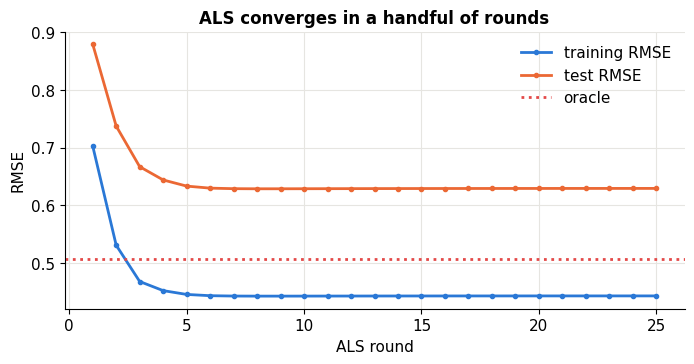

In [7]:
def mf_als(k, lam, n_iter=20, use_bias=True, seed=1, history=False):
    """Matrix factorization by alternating ridge regressions on the observed entries only."""
    rr = np.random.default_rng(seed)
    U, V = rr.normal(0, 0.1, (n_users, k)), rr.normal(0, 0.1, (n_items, k))
    bu, bi = np.zeros(n_users), np.zeros(n_items)
    hist = []
    for it in range(n_iter):
        for i in range(n_users):                                # each user: ridge regression on the items they rated
            j = M[i]; A = np.c_[V[j], np.ones(j.sum())] if use_bias else V[j]
            y = ratings[i, j] - mu - (bi[j] if use_bias else 0)
            sol = np.linalg.solve(A.T @ A + lam * np.eye(A.shape[1]), A.T @ y)
            U[i] = sol[:k]; bu[i] = sol[k] if use_bias else 0
        for j_ in range(n_items):                               # each item: ridge regression on the users who rated it
            i = M[:, j_]; A = np.c_[U[i], np.ones(i.sum())] if use_bias else U[i]
            y = ratings[i, j_] - mu - (bu[i] if use_bias else 0)
            sol = np.linalg.solve(A.T @ A + lam * np.eye(A.shape[1]), A.T @ y)
            V[j_] = sol[:k]; bi[j_] = sol[k] if use_bias else 0
        if history:
            P = mu + bu[:, None] + bi[None, :] + U @ V.T
            hist.append((rmse(P, train_idx), rmse(P, test_idx)))
    P = mu + bu[:, None] + bi[None, :] + U @ V.T
    return (P, U, V, bu, bi, hist) if history else (P, U, V, bu, bi)

# Baseline: biases only (k = 0)
P_bias = mf_als(0, 3.0)[0]
results["biases only"] = rmse(P_bias)
t0 = time.time(); P_mf, U_mf, V_mf, bu_mf, bi_mf, hist = mf_als(5, 1.0, n_iter=25, history=True)
results["matrix factorization (r=5, λ=1)"] = rmse(P_mf)
print(f"biases only:                 test RMSE {results['biases only']:.3f}")
print(f"matrix factorization, r = 5: test RMSE {results['matrix factorization (r=5, λ=1)']:.3f}   ({time.time() - t0:.1f} s)")
print(f"oracle:                      test RMSE {results['oracle (true preferences)']:.3f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(range(1, len(hist) + 1), [h[0] for h in hist], "o-", ms=3, label="training RMSE"); ax.plot(range(1, len(hist) + 1), [h[1] for h in hist], "o-", ms=3, label="test RMSE")
ax.axhline(results["oracle (true preferences)"], color=C["red"], ls=":", label="oracle"); ax.set(xlabel="ALS round", ylabel="RMSE", title="ALS converges in a handful of rounds"); ax.legend()
plt.show()

Biases alone beat the global mean, and rank-5 factorization closes most of the remaining gap to the oracle (0.89 → 0.63, against the oracle's 0.51). The training RMSE drops well below the test RMSE: the model fits some of the training noise, which is what λ and the rank control.

### Choosing the rank and λ

ISYE W4: *large rank → more expressive, fits better (too large overfits); small rank → better generalization.* Let's map the test error over both knobs:

In [8]:
ranks, lams = [1, 2, 3, 5, 8, 12, 20], [0.3, 1, 3, 10, 30]
grid = {}
for k in ranks:
    for lam in lams:
        P = mf_als(k, lam, n_iter=12)[0]
        grid[(k, lam)] = (rmse(P, train_idx), rmse(P, test_idx))
TR = np.array([[grid[(k, l)][0] for l in lams] for k in ranks]); TE = np.array([[grid[(k, l)][1] for l in lams] for k in ranks])
best = np.unravel_index(TE.argmin(), TE.shape)

def plot_grid(rank_index=3):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
    im = axes[0].imshow(TE, cmap="viridis_r", aspect="auto"); plt.colorbar(im, ax=axes[0], label="test RMSE")
    for a in range(len(ranks)):
        for b in range(len(lams)): axes[0].text(b, a, f"{TE[a, b]:.3f}", ha="center", va="center", color="white" if TE[a, b] > TE.mean() else "k", fontsize=8)
    axes[0].add_patch(plt.Rectangle((best[1] - 0.5, best[0] - 0.5), 1, 1, fill=False, ec=C["red"], lw=3))
    axes[0].axhline(rank_index, color=C["orange"], lw=2, alpha=0.6)
    axes[0].set(xticks=range(len(lams)), xticklabels=lams, yticks=range(len(ranks)), yticklabels=ranks, xlabel="λ", ylabel="rank r", title="test RMSE (red box = best)"); axes[0].grid(False)
    axes[1].semilogx(lams, TR[rank_index], "o-", label="training"); axes[1].semilogx(lams, TE[rank_index], "o-", label="test")
    axes[1].axhline(results["oracle (true preferences)"], color=C["red"], ls=":", label="oracle")
    axes[1].set(xlabel="λ", ylabel="RMSE", ylim=(0, 1.3), title=f"rank r = {ranks[rank_index]}: small λ overfits, big λ underfits"); axes[1].legend()
    fig.tight_layout(); plt.show()

interact(plot_grid, rank_index=IntSlider(value=3, min=0, max=len(ranks) - 1, description="rank row"));

The best cell sits at rank 5 (the true number of genres) with moderate λ. Ranks 1–2 can't express five genres, so they underfit whatever λ is. High ranks with tiny λ memorize the training ratings (training RMSE far below the oracle, test RMSE way up). Large λ shrinks all the factors to zero, leaving the biases-only model. Regularization and rank trade off against each other: a high rank survives if λ is large enough to rein it in.

### The same model, trained by SGD

The Netflix Prize's popular "Funk SVD" trained the same model by **stochastic gradient descent** instead: visit observed ratings in random order, compute the error $e = x_{ij} - \hat x_{ij}$, and nudge the parameters downhill:

$$u_i \leftarrow u_i + \eta\,(e\,v_j - \lambda' u_i), \qquad v_j \leftarrow v_j + \eta\,(e\,u_i - \lambda' v_j), \qquad b_i \leftarrow b_i + \eta(e - \lambda' b_i), \;\dots$$

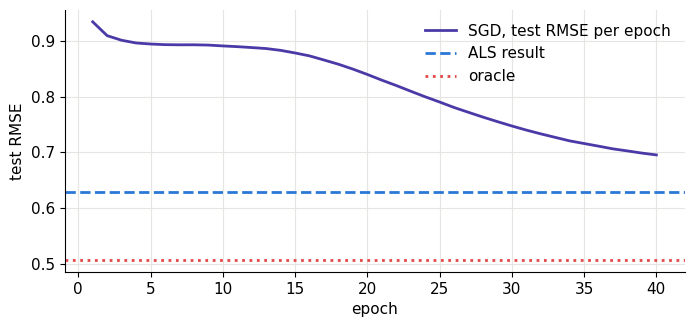

SGD: test RMSE 0.695 after 40 epochs (6.2 s)


In [9]:
def mf_sgd(k=5, lam=0.05, lr=0.01, epochs=40, seed=0):
    rr = np.random.default_rng(seed)
    U, V = rr.normal(0, 0.1, (n_users, k)), rr.normal(0, 0.1, (n_items, k)); bu, bi = np.zeros(n_users), np.zeros(n_items)
    curve = []
    for ep in range(epochs):
        for i, j in train_idx[rr.permutation(len(train_idx))]:
            e = ratings[i, j] - (mu + bu[i] + bi[j] + U[i] @ V[j])
            bu[i] += lr * (e - lam * bu[i]); bi[j] += lr * (e - lam * bi[j])
            U[i], V[j] = U[i] + lr * (e * V[j] - lam * U[i]), V[j] + lr * (e * U[i] - lam * V[j])
        curve.append(rmse(mu + bu[:, None] + bi[None, :] + U @ V.T))
    return mu + bu[:, None] + bi[None, :] + U @ V.T, curve

t0 = time.time(); P_sgd, curve = mf_sgd()
results["matrix factorization, SGD"] = rmse(P_sgd)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(range(1, len(curve) + 1), curve, color=C["violet"], label="SGD, test RMSE per epoch")
ax.axhline(results["matrix factorization (r=5, λ=1)"], color=C["blue"], ls="--", label="ALS result")
ax.axhline(results["oracle (true preferences)"], color=C["red"], ls=":", label="oracle"); ax.set(xlabel="epoch", ylabel="test RMSE"); ax.legend(); plt.show()
print(f"SGD: test RMSE {results['matrix factorization, SGD']:.3f} after {len(curve)} epochs ({time.time() - t0:.1f} s)")

SGD gets to about 0.70 in 40 epochs and is still improving when we stop: it spends its first dozen epochs learning the biases, and only then do the factors grow out of their small random start. With more epochs or a tuned learning rate it reaches ALS's quality; ALS gets there in five rounds because each round solves its sub-problems exactly. ALS solves exact sub-problems and parallelizes neatly (every user's update is independent), which is why large systems like Spark's recommender use it; SGD is simpler, handles any differentiable loss, and is the bridge to neural recommenders trained with the same loop (notebook 20).

---
## 6. What the embeddings learned

The factor vectors are **embeddings**: users and items placed in the same $r$-dimensional space, where a large dot product means a good match. The model was never told the genres. Did it discover them?

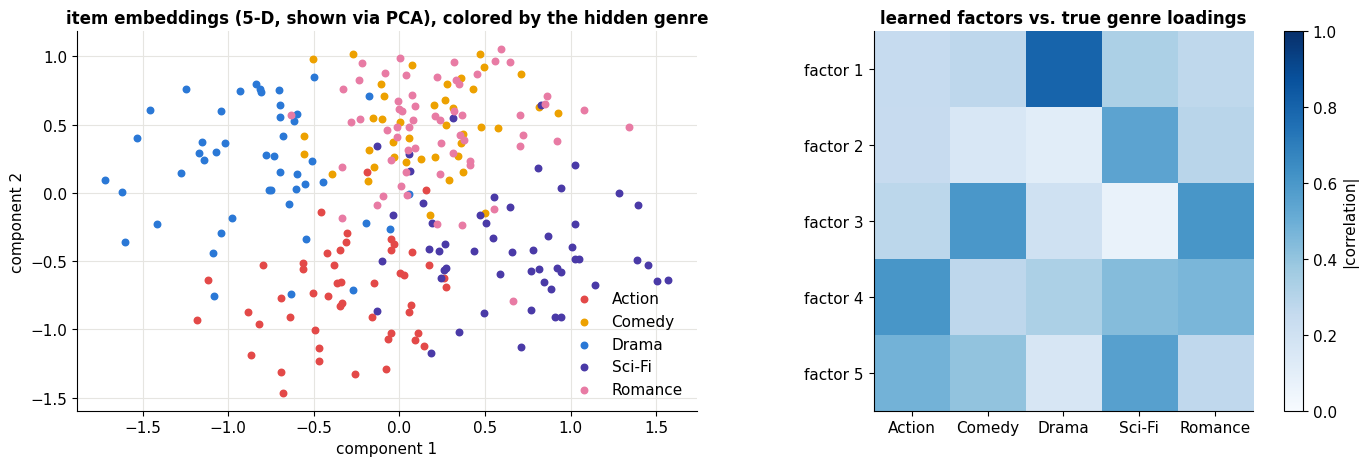

k-means (k=5) on the 5-D item embeddings vs. the hidden genres: ARI = 0.79
best linear combination of the 5 learned factors vs. each true genre loading (correlation): {'Action': 0.875, 'Comedy': 0.857, 'Drama': 0.905, 'Sci-Fi': 0.886, 'Romance': 0.879}


In [10]:
from sklearn.decomposition import PCA as _PCA
V2 = _PCA(2).fit_transform(V_mf)
corr = np.corrcoef(np.c_[V_mf, item_f].T)[:5, 5:]               # learned factors vs true genre loadings
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
gcols = [C["red"], C["yellow"], C["blue"], C["violet"], C["magenta"]]
for g in range(n_genres):
    axes[0].scatter(*V2[item_genre == g].T, s=22, color=gcols[g], label=genres[g])
axes[0].set(title="item embeddings (5-D, shown via PCA), colored by the hidden genre", xlabel="component 1", ylabel="component 2"); axes[0].legend()
im = axes[1].imshow(np.abs(corr), cmap="Blues", vmin=0, vmax=1); plt.colorbar(im, ax=axes[1], label="|correlation|")
axes[1].set(xticks=range(5), xticklabels=genres, yticks=range(5), yticklabels=[f"factor {k + 1}" for k in range(5)], title="learned factors vs. true genre loadings"); axes[1].grid(False)
fig.tight_layout(); plt.show()
from sklearn.cluster import KMeans as _KM
from sklearn.metrics import adjusted_rand_score as _ari
print(f"k-means (k=5) on the 5-D item embeddings vs. the hidden genres: ARI = {_ari(item_genre, _KM(5, n_init=10, random_state=0).fit_predict(V_mf / np.linalg.norm(V_mf, axis=1, keepdims=True))):.2f}")
Vb = np.c_[V_mf, np.ones(n_items)]
best_cc = [np.corrcoef(Vb @ np.linalg.lstsq(Vb, item_f[:, g], rcond=None)[0], item_f[:, g])[0, 1] for g in range(n_genres)]
print("best linear combination of the 5 learned factors vs. each true genre loading (correlation):", {str(g): round(float(c), 3) for g, c in zip(genres, best_cc)})

Even squeezed from 5-D down to 2-D, movies of the same genre occupy their own regions (with overlap; two dimensions can't hold five directions), and clustering the full 5-D embeddings (notebook 14) recovers the genres well, as the ARI printout shows. All of this was discovered from nothing but who rated what how highly. The individual learned factors don't line up one-to-one with genres (the right panel is mixed), because the factorization is only identified up to a **rotation**: $UV^\top = (UQ)(VQ)^\top$ for any orthogonal $Q$. But the five factors together span nearly the same space: a linear combination of them tracks each true genre loading with correlation around 0.9 (not 1, because the model learned them from noisy, sparse ratings and regularization shrinks rarely rated movies). In real systems the factors often turn out interpretable anyway ("serious vs. escapist", "aimed at kids"), but nothing forces them to be.

Now use the model. Pick a user and compare their true tastes with what the model recommends among unseen movies:

In [11]:
def recommend(user=7, n=8):
    seen = observed[user]
    scores = np.where(seen, -np.inf, P_mf[user])
    top = np.argsort(-scores)[:n]
    fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw=dict(width_ratios=[1, 1.4]))
    axes[0].bar(genres, user_f[user], color=gcols); axes[0].axhline(0, color=C["ink"], lw=0.8)
    axes[0].set(title=f"user {user}'s TRUE genre tastes (hidden from the model)", ylabel="taste")
    axes[1].barh(range(n)[::-1], P_mf[user, top], color=[gcols[item_genre[j]] for j in top])
    axes[1].set(yticks=range(n)[::-1], yticklabels=[f"{titles[j]}  (true pref {true_pref[user, j]:.1f})" for j in top], xlim=(1, 5.3),
                xlabel="predicted rating", title=f"top {n} unseen movies for user {user} (rated {seen.sum()} movies)")
    fig.tight_layout(); plt.show()

interact(recommend, user=IntSlider(value=7, min=0, max=n_users - 1, description="user"), n=IntSlider(value=8, min=3, max=15, description="how many"));

The recommendations concentrate on the genres the user secretly likes (tall bars on the left), and their true preferences for the recommended movies are high. Users with very few ratings get blander, more popularity-driven lists, because the regularization pulls their factors toward zero, leaving mostly the item biases.

---
## 7. Collaborative filtering: similar users, similar items

The older and simpler family (ISYE W4) skips latent factors entirely and predicts from **neighbors**:

- **User-based:** to predict user $u$'s rating of item $i$, find users similar to $u$ who rated $i$, and average their ratings, weighted by similarity.
- **Item-based:** find items similar to $i$ that $u$ rated, and average $u$'s own ratings of them, weighted by similarity.

Everything depends on the **similarity** measure. ISYE's two:

$$\text{sim}_{\cos}(x, y) = \frac{x^\top y}{\|x\|\|y\|}, \qquad \text{sim}_{\text{Pearson}}(x, y) = \frac{\sum_k(x_k - \bar x)(y_k - \bar y)}{\sqrt{\sum_k(x_k - \bar x)^2}\sqrt{\sum_k(y_k - \bar y)^2}} = \text{sim}_{\cos}(x - \bar x, y - \bar y),$$

computed over the items both users rated. Pearson is cosine after **centering**, which removes each user's personal rating scale. ISYE's worked example (users 1 and 2 co-rated items 1, 2, 4):

In [12]:
x_, y_ = np.array([5, 4, 1.0]), np.array([4, 5, 1.0])
cos = x_ @ y_ / (np.linalg.norm(x_) * np.linalg.norm(y_))
pear = np.corrcoef(x_, y_)[0, 1]
print(f"cosine = {cos:.3f}   Pearson = {pear:.3f}")
# A generous rater and a harsh rater with the same ORDER of preferences
gen, harsh = np.array([5, 5, 4, 5, 4.0]), np.array([3, 3, 1, 3, 1.0])
print(f"generous vs harsh rater with identical taste: cosine {gen @ harsh / np.linalg.norm(gen) / np.linalg.norm(harsh):.3f}, Pearson {np.corrcoef(gen, harsh)[0, 1]:.3f}")
opp = np.array([4, 4, 5, 4, 5.0])
print(f"two generous raters with OPPOSITE tastes:       cosine {gen @ opp / np.linalg.norm(gen) / np.linalg.norm(opp):.3f}, Pearson {np.corrcoef(gen, opp)[0, 1]:.3f}")

cosine = 0.976   Pearson = 0.885
generous vs harsh rater with identical taste: cosine 0.951, Pearson 1.000
two generous raters with OPPOSITE tastes:       cosine 0.977, Pearson -1.000


Both match the slide (0.976 and 0.88). The two extra lines show why centering matters: with all-positive star ratings, **cosine similarity is high for almost any pair** (two generous raters with opposite tastes still score 0.97), because every vector points into the same positive corner. Pearson sees through the rating scale: identical tastes at different generosity get 1.0, opposite tastes get −1.

And ISYE's two predictions, reproduced:

In [13]:
# User-based: neighbors of the target user rated the item 4 and 2, with similarities 0.99 and 0.80
print(f"user-based: (0.99×4 + 0.80×2) / (0.99 + 0.80) = {(0.99 * 4 + 0.8 * 2) / (0.99 + 0.8):.2f}")
# Item-based: the target user rated two similar items 1 and 2, with similarities 0.99 and 1.00
print(f"item-based: (0.99×1 + 1.00×2) / (0.99 + 1.00) = {(0.99 * 1 + 1.0 * 2) / (0.99 + 1.0):.2f}")

user-based: (0.99×4 + 0.80×2) / (0.99 + 0.80) = 3.11
item-based: (0.99×1 + 1.00×2) / (0.99 + 1.00) = 1.50


Now a full implementation. With Pearson similarity, the standard prediction also works in centered terms: start from the target's own mean and add the neighbors' weighted **deviations** from their means, $\hat x_{ui} = \bar x_u + \frac{\sum_v \text{sim}(u,v)(x_{vi} - \bar x_v)}{\sum_v \text{sim}(u,v)}$, using the $K$ most similar neighbors with positive similarity.

In [14]:
def cf_predict(kind="item", sim="pearson", K=20, pairs=test_idx):
    A = R_train if kind == "user" else R_train.T                # rows = the entities we compare
    mask = ~np.isnan(A); means = np.where(mask.any(1), np.nanmean(np.where(mask, A, np.nan), 1), mu)
    Z = np.where(mask, A - (means[:, None] if sim == "pearson" else 0), 0.0)
    norms = np.sqrt((Z ** 2).sum(1)) + 1e-9
    S = (Z @ Z.T) / np.outer(norms, norms); np.fill_diagonal(S, 0)
    out = np.empty(len(pairs))
    for t, (u_, i_) in enumerate(pairs if kind == "user" else pairs[:, ::-1]):
        cand = np.flatnonzero(mask[:, i_])                      # neighbors who have a rating for the target
        if len(cand) == 0: out[t] = means[u_]; continue
        top = cand[np.argsort(-S[u_, cand])[:K]]; w = np.clip(S[u_, top], 0, None)
        if w.sum() < 1e-9: out[t] = means[u_]; continue
        if sim == "pearson": out[t] = means[u_] + (w * (A[top, i_] - means[top])).sum() / w.sum()
        else: out[t] = (w * A[top, i_]).sum() / w.sum()
    return np.clip(out, 1, 5)

def rmse_pairs(pred, pairs=test_idx): return np.sqrt(np.mean((pred - ratings[pairs[:, 0], pairs[:, 1]]) ** 2))

rows = []
for kind in ["user", "item"]:
    for sim in ["cosine", "pearson"]:
        for K in [10, 30, 100]:
            rows.append(dict(method=f"{kind}-based", similarity=sim, K=K, test_RMSE=rmse_pairs(cf_predict(kind, sim, K))))
cf_tab = pd.DataFrame(rows)
cf_tab.pivot_table(index=["method", "similarity"], columns="K", values="test_RMSE").round(3)

K                        10     30     100
method     similarity                     
item-based cosine      0.908  0.944  0.962
           pearson     0.744  0.768  0.775
user-based cosine      0.878  0.896  0.933
           pearson     0.781  0.787  0.801

Three lessons, consistent with what the Netflix Prize and decades of practice found:

1. **Pearson beats cosine** by a wide margin, for the reason shown above: centering removes rating-scale differences that cosine mistakes for taste.
2. **Item-based beats user-based** here. Items have many more ratings each than users do (each movie is rated by ~50 users, each user rates ~30 movies), so item–item similarities are estimated more reliably, and they change slowly, so they can be precomputed (Amazon's original recommender was item-based for this reason). ISYE W4 calls item-based "more stable".
3. **Fewer neighbors** (K ≈ 10) work best here; averaging over 100 "neighbors" mixes in weakly similar ones and drifts toward the average.

> 🤔 **Question: What information do we lose when we drop latent factors?** (ISYE W4)
>
> Neighborhood methods only connect users through items they **both** rated. Two users who share a love of sci-fi but happen to have rated different sci-fi movies look unrelated (zero overlap, no similarity), even though they have the same taste. Latent factors generalize across items: rating *any* sci-fi movie highly moves your vector in the sci-fi direction, and every other sci-fi movie benefits. With sparse data, that sharing is worth a lot, as the next comparison shows. HW2's variant, similarity $e^{-d(u,v)^2}$ built from a distance between users' **feature vectors** (age, major, ...), is a third option that works even without overlapping ratings, a first step toward the content-based methods in section 10.

---
## 8. Head to head on held-out ratings

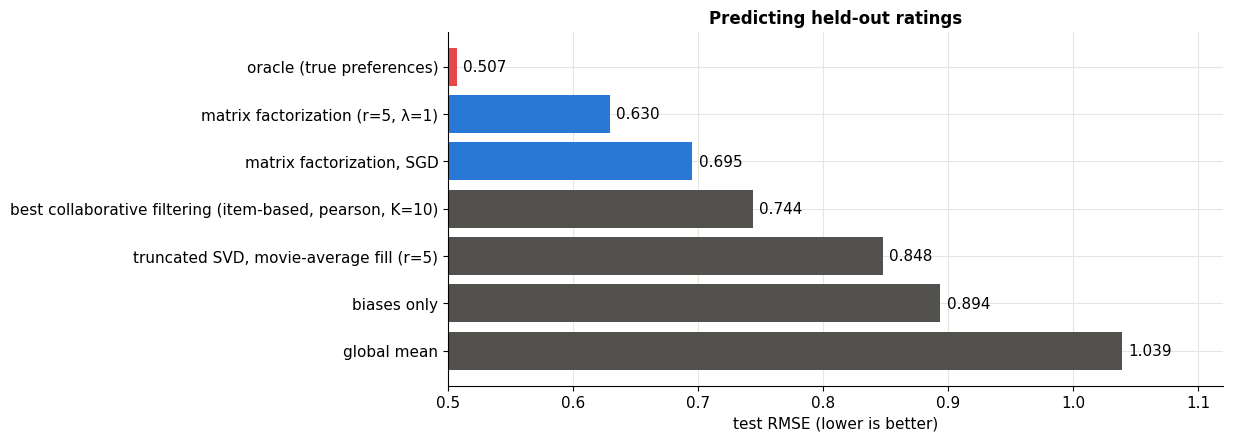

In [15]:
best_cf = cf_tab.loc[cf_tab.test_RMSE.idxmin()]
results[f"best collaborative filtering ({best_cf.method}, {best_cf.similarity}, K={best_cf.K})"] = best_cf.test_RMSE
results["truncated SVD, movie-average fill (r=5)"] = rmse(truncated_svd_fill(np.broadcast_to(item_means, ratings.shape), 5))
order_r = sorted(results, key=results.get, reverse=True)
fig, ax = plt.subplots(figsize=(10, 4.6))
cols_r = [C["red"] if "oracle" in k else C["blue"] if "factorization" in k else C["muted"] for k in order_r]
ax.barh(range(len(order_r)), [results[k] for k in order_r], color=cols_r)
for i_, k in enumerate(order_r): ax.text(results[k] + 0.005, i_, f"{results[k]:.3f}", va="center")
ax.set(yticks=range(len(order_r)), yticklabels=order_r, xlabel="test RMSE (lower is better)", xlim=(0.5, 1.12), title="Predicting held-out ratings")
plt.show()

Matrix factorization (ALS, then SGD) wins clearly; the best neighborhood method (item-based, Pearson) lands between the bias baseline and factorization, about level with SVD on the movie-average-filled matrix. Nothing reaches the oracle: with about 30 noisy ratings per user, part of each user's taste simply isn't recoverable. On real data the ordering is usually the same, with smaller gaps, and the strongest systems blend several models (the Netflix Prize was won by an ensemble of hundreds).

---
## 9. From predicted ratings to recommendations

A recommender doesn't show you RMSE; it shows you a **short ranked list**. What matters is whether the top few items are ones you'd like. Common metrics: **precision@N** (what fraction of the top N are relevant) and **recall@N** (what fraction of the relevant items made the top N). Here "relevant" means a held-out rating of 4 or 5 stars, and we rank each user's unrated (in training) movies.

One subtlety: we can only score items the user actually rated in the test set, since for everything else we don't know the answer. That's the missing-not-at-random problem again, and it favors popular items (they're more likely to have test ratings at all).

In [16]:
test_mat = np.zeros_like(observed); test_mat[test_idx[:, 0], test_idx[:, 1]] = True
relevant = test_mat & (ratings >= 4)
pop_score = np.broadcast_to(M.sum(0).astype(float), ratings.shape)       # "most rated" baseline
mean_score = np.broadcast_to(item_means, ratings.shape)                  # "highest average" baseline
def precision_recall_at(scores, N=10):
    P, Rc = [], []
    for u_ in range(n_users):
        if relevant[u_].sum() == 0: continue
        cand = np.flatnonzero(~M[u_])
        top = cand[np.argsort(-scores[u_, cand])[:N]]
        hits = relevant[u_, top].sum(); P.append(hits / N); Rc.append(hits / relevant[u_].sum())
    return np.mean(P), np.mean(Rc)
rows = []
for name, sc in [("random", np.random.default_rng(0).random(ratings.shape)), ("most popular", pop_score), ("highest average rating", mean_score),
                 ("matrix factorization", P_mf), ("oracle (true preference)", true_pref)]:
    p_, r__ = precision_recall_at(sc); rows.append(dict(method=name, **{"precision@10": p_, "recall@10": r__}))
pd.DataFrame(rows).set_index("method").round(3)

,precision@10,recall@10
method,,
random,0.028,0.041
most popular,0.175,0.300
highest average rating,0.036,0.064
matrix factorization,0.113,0.218
oracle (true preference),0.108,0.201


Matrix factorization ranks far better than random or "highest average", but notice how strong the dumb **popularity** baseline is under this protocol. That's the bias at work: popular movies are watched (and thus test-rated) more often, so "recommend the most-rated movies" collects many hits for free. The "oracle", which ranks by true preference, does *worse* than popularity here, because it happily recommends obscure movies the user would love but never watched, which can't count as hits. Offline ranking evaluation on logged data rewards predicting what people **will watch**, not only what they'd **like**. Real systems lean on online A/B tests for this reason.

---
## 10. Real-world problems

**Cold start.** A brand-new user or item has no ratings, so it has no factor vector and no neighbors. Remedies: ask new users a few onboarding questions, start with popular items, and use **content features** (genre, cast, description text, user demographics). *Content-based* recommenders predict from such features; *hybrid* models combine them with collaborative signals.

**Implicit feedback.** Most real data isn't star ratings but clicks, views, purchases, watch time. There are no negative examples, only "interacted" vs. "didn't (yet)". Implicit-feedback matrix factorization treats every unobserved pair as a weak negative with low confidence (Hu, Koren & Volinsky, 2008), and ranking losses (such as BPR) train the model to score interacted items above others.

**Feedback loops.** The system recommends popular items → they get more views → they look even more popular. Without care, recommenders narrow what users see and starve the long tail. Exploration (occasionally showing less-certain items), diversity constraints, and debiasing for exposure are active topics.

**Modern systems.** The core idea, users and items as learned embeddings scored by a dot product, survives in today's industrial recommenders. The "two-tower" models used by large platforms compute the user and item vectors with neural networks from features and history (notebook 19 onward), retrieve candidates by fast nearest-neighbor search over item embeddings, then re-rank with a heavier model. Sequence models (transformers, notebook 25) predict the next item from a user's recent history.

---
## 11. Summary

| | Truncated SVD | Matrix factorization (ALS / SGD) | User-based CF | Item-based CF |
|---|---|---|---|---|
| Core idea | best low-rank approximation | $\hat x_{ij} = \mu + b_i + c_j + u_i^\top v_j$ | similar users' ratings | user's ratings of similar items |
| Uses missing entries? | must fill them (bad) | **ignores** them | ignores | ignores |
| Hyperparameters | rank | rank, λ | similarity, K | similarity, K |
| Strengths | simple, exact on full data | accurate, generalizes across items, embeddings | intuitive, no training | stable, precomputable, explainable ("because you liked…") |
| Weaknesses | biased by fill-in | non-convex, cold start | sparse overlaps, scales poorly in users | cold start |

**The big ideas:** user–item data is sparse but approximately low rank; fit the low-rank model **to observed entries only**; alternating least squares turns a non-convex problem into a sequence of easy ridge regressions (block coordinate descent again, like k-means and EM); regularization and biases matter as much as the factors; and evaluating recommenders is subtle because the data you see depends on what users chose to look at.

That completes the tour of unsupervised building blocks except one: **anomaly detection** (notebook 18), which asks the opposite question from clustering: which points don't belong to *any* group?

### ✏️ Exercises

1. Derive the regularized ALS update $u_i = (V_{\Omega_i}^\top V_{\Omega_i} + \lambda I)^{-1}V_{\Omega_i}^\top x_{i,\Omega_i}$ by setting the gradient of the objective with respect to $u_i$ to zero.
2. Run the $r = 1$ ALS on ISYE's 5 × 5 example from several random starting points. Do the predictions for the missing entries change? Why can the factors themselves differ while the predictions don't?
3. Show that with $\lambda > 0$ the scale ambiguity of section 4 disappears: among all $(cu, v/c)$, which $c$ minimizes $\lambda(\|u\|^2 + \|v\|^2)$?
4. Implement HW2's distance-based similarity $\text{sim}(u, v) = e^{-d(u,v)^2}$ with Euclidean, Manhattan, and Hamming distances between users' rating vectors (missing = 0), plug it into `cf_predict`, and compare with Pearson.
5. Make the data **colder**: keep only 5% of the observed ratings for training. How do biases-only, item-based CF, and matrix factorization rank now? What rank and λ are best?
6. Try the real thing: download MovieLens 100K (https://grouplens.org/datasets/movielens/100k/), load `u.data`, and rerun sections 5, 7 and 8. Real data has no oracle; what's the best test RMSE you can reach?
7. Change the simulation so that users pick movies **at random** (remove the `exp(0.5 * ...)` factor). Recompute the precision@10 table. Does popularity still look so strong?

### References

- ISYE 4600 W4 (Recommender Systems) and HW2 Q5.
- Y. Koren, R. Bell & C. Volinsky, *Matrix Factorization Techniques for Recommender Systems*, IEEE Computer (2009).
- S. Funk, *Netflix Update: Try This at Home* (blog, 2006): SGD matrix factorization.
- B. Sarwar, G. Karypis, J. Konstan & J. Riedl, *Item-based Collaborative Filtering Recommendation Algorithms*, WWW (2001); G. Linden, B. Smith & J. York, *Amazon.com Recommendations: Item-to-Item Collaborative Filtering*, IEEE Internet Computing (2003).
- Y. Hu, Y. Koren & C. Volinsky, *Collaborative Filtering for Implicit Feedback Datasets*, ICDM (2008).
- E. Candès & B. Recht, *Exact Matrix Completion via Convex Optimization*, Foundations of Computational Mathematics (2009).
- F. M. Harper & J. Konstan, *The MovieLens Datasets: History and Context*, ACM TiiS (2015).

**Next → [18 · Anomaly Detection](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/18_anomaly_detection.ipynb)**